# М01. Можно ли принять решение по красивому прогнозу?

**Разбор опубликованного научного кейса · вводный модуль · стандартный Python и matplotlib.**

В исследовании растворимости нужно решить, какие вещества и условия проверять экспериментально. Измерить всё сразу нельзя; расчёт помогает расставить приоритеты. Но что именно разрешает заключить прогноз, особенно когда средняя ошибка выглядит приемлемой?

В работе Delaney (2004) исследуется прогноз водной растворимости из молекулярных свойств. Мы разберём доступный обработанный архив: рядом стоят измеренная logS и уже рассчитанная logS. Вы пройдёте путь от доверия средней метрике к выбору следующего измерения, обнаружив существенное расхождение **в реальных строках**, без придуманного механизма и без вымышленных реплик автора статьи.

**Ваша роль:** исследователь, который готовит аргументированный план проверки, а не просто выдаёт число. Успех — объяснить, что узнали, какой вывод пока не поддержан и каким наблюдением его можно проверить.

**Маршрут:** объект/представление → источник → прогноз → сравнение с наблюдениями → неожиданность → ограничения → решение → досье и карта. После разбора — [три связанных самостоятельных кейса](02_independent_lab.ipynb). [Источник и адаптация](RESEARCH_SOURCE.md), [установка](README.md#окружение).


## 1. Сначала разберёмся, что изучает курс

| Уровень | Пример | Какой вопрос решаем |
|---|---|---|
| Объект/образец | Вещество определённой формы в среде | Что именно приготовили или измерили? |
| Представление | Имя, SMILES, координаты | Как записали объект и что потеряли? |
| Модель/алгоритм | Формула, QSPR, электронный расчёт | Какое приближение связывает входы с выходом? |
| Наблюдение | Измерение с условиями и методом | С чем сравнивать вычисление? |
| Решение | Следующее измерение или отказ от вывода | Что меняется после результата? |

Хемоинформатика работает с записями и признаками; физическая химия связывает свойства со средой и равновесием; QM и молекулярная механика описывают разные приближения; статистика помогает оценивать ошибки; аналитическая химия нужна для независимых измерений. Ни одна из дисциплин не заменяет остальные.

Курс дальше разберёт ксантины/истрадефиллин и A2A как линию A; самостоятельное досье B будет связано с аторвастатином/HMGCR и печёночной экспозицией. **ESOL здесь — опубликованный учебный стенд для проверки доказательств**, а не набор данных по проникновению этих веществ через ГЭБ или в печень. Эти endpoints нельзя подменять растворимостью.


## 2. Прогноз до расчёта

Представьте, что средняя ошибка модели меньше одной единицы logS. Разрешает ли это считать каждый её прогноз надёжным? Как вы отличили бы неудачный прогноз от несопоставимого измерения? Запишите первоначальный ответ; его можно пересмотреть без штрафа.

Сейчас нам не нужны SMILES-парсер, RDKit или fitting новой модели. Нужны проверенные байты и понимание двух столбцов. Следующая ячейка показывает интерпретатор и рабочую папку, не меняя системную среду.


In [1]:
from pathlib import Path
import sys, json, csv, math, statistics, hashlib, importlib.util, os
import matplotlib.pyplot as plt
from IPython.display import display, Image
MODULE = next(candidate for parent in [Path.cwd(), *Path.cwd().parents]
              for candidate in [parent, parent/'course_source/modules/M01']
              if (candidate/'m01.py').is_file())
if str(MODULE) not in sys.path:
    sys.path.insert(0, str(MODULE))
from m01 import META, MEASURED, PREDICTED, locate_snapshot, checksum, format_feedback, metric_invariants, create_dossier
OUT = Path(os.environ.get('M01_WORK_DIR', str(MODULE/'learner_work')))/'guided'
OUT.mkdir(parents=True, exist_ok=True)
print('Python:', sys.executable)
print('RDKit required: no; installed:', importlib.util.find_spec('rdkit') is not None)


Python: C:\Users\Miakhlov\Documents\GitHub\Computational chemistry_course\tmp\issue4-research-m01-20261117\course_source\modules\M01\.venv\Scripts\python.exe
RDKit required: no; installed: False


## 3. Какой именно источник открыт?

В статье сообщается о разработке модели на 2874 измерениях. Наш CSV — **вторичный snapshot DeepChem на 1128 строк**, с отдельными колонками measured и predicted. Это не полный исходный training set и не воспроизведение fitting Delaney.

Проверяем SHA256 и схему перед чтением. Имена не являются уникальными химическими идентификаторами, а порядковый `row_id` — только адрес строки этого snapshot. Если локального файла ещё нет, выполните `fetch_data.py` из инструкции; во время исследования сеть не требуется.


In [2]:
raw_path=locate_snapshot()
raw_sha=checksum(raw_path)
with raw_path.open(encoding='utf-8',newline='') as stream:
    reader=csv.DictReader(stream)
    columns=reader.fieldnames
    raw=list(reader)
print('SHA256:',raw_sha,'rows:',len(raw))
print('Measurement:',MEASURED)
print('Prediction:',PREDICTED)
print('Missing conditions:',META['missing_conditions'])
assert len(raw)==1128 and raw_sha==META['sha256']


SHA256: 8c06a76f0c6487d29ab0f903e6a7a7139f189ab3c1178f159c8be8964602f189 rows: 1128
Measurement: measured log solubility in mols per litre
Prediction: ESOL predicted log solubility in mols per litre
Missing conditions: ['pH', 'temperature', 'solid form', 'individual measurement uncertainty']


### Разделяем измерение и вычисление

`logS` означает log10(S / (mol·L⁻¹)). Прогноз и измерение должны быть в одной шкале. При отрицательном logS концентрация положительна: логарифм не является самой концентрацией. Формируем новую таблицу, сохраняя номер строки и исходные строки SMILES; химическую идентичность по ним пока не устанавливаем.


In [3]:
rows=[{'row_id':i,'name':r['Compound ID'],'smiles':r['smiles'],
       'measured':float(r[MEASURED]),'predicted':float(r[PREDICTED])}
      for i,r in enumerate(raw)]
display([{k:r[k] for k in ['row_id','name','measured','predicted']} for r in rows[:3]])
assert all(math.isfinite(r['measured']) and math.isfinite(r['predicted']) for r in rows)


[{'row_id': 0,
  'name': 'Amigdalin',
  'measured': -0.77,
  'predicted': -0.9740000000000001},
 {'row_id': 1, 'name': 'Fenfuram', 'measured': -3.3, 'predicted': -2.885},
 {'row_id': 2,
  'name': 'citral',
  'measured': -2.06,
  'predicted': -2.5789999999999997}]

## 4. Сравнение, которое можно повторить

До анализа зафиксировано распределение учебных записей: `row_id % 4 == 0` для разбора, `== 1` для самостоятельного переноса. Остальные здесь не используем. Такое правило не выбирает удобные ошибки. Однако это **не train/test**, не выделение независимых молекул и не доказательство обобщения: происхождение fitting готового predicted-столбца здесь не контролируется.

Остаток ε = predicted − measured. MAE — среднее |ε|; RMSE — корень среднего ε². RMSE сильнее реагирует на крупные отклонения. Сначала смотрим строки и остатки, затем агрегируем.


In [4]:
guided=[r for r in rows if r['row_id']%4==0]
residuals=[r['predicted']-r['measured'] for r in guided]
display([{'row_id':r['row_id'],'name':r['name'],'residual_logS':e}
         for r,e in list(zip(guided,residuals))[:5]])
assert len(guided)==282


[{'row_id': 0, 'name': 'Amigdalin', 'residual_logS': -0.20400000000000007},
 {'row_id': 4, 'name': 'Thiophene', 'residual_logS': -0.9019999999999997},
 {'row_id': 8, 'name': 'Dieldrin', 'residual_logS': 1.7569999999999997},
 {'row_id': 12, 'name': '1-Pentene ', 'residual_logS': 0.6700000000000004},
 {'row_id': 16,
  'name': '2-Methylbutanol',
  'residual_logS': -0.5570000000000002}]

In [5]:
mae=sum(abs(e) for e in residuals)/len(residuals)
rmse=math.sqrt(sum(e*e for e in residuals)/len(residuals))
print({'n':len(residuals),'MAE_logS':mae,'RMSE_logS':rmse})
assert 0<=mae<=rmse and math.isfinite(rmse)


{'n': 282, 'MAE_logS': 0.7690035460992907, 'RMSE_logS': 1.0037640277496775}


**Пауза для интерпретации.** Мы получили средние ошибки именно выбранных архивных строк. Они не являются процентом точности, гарантией для каждой молекулы или независимой test accuracy. Прежде чем рекомендовать использование прогноза, посмотрим, не скрывает ли среднее большой хвост отклонений.

## 5. График задаёт следующий вопрос

На диагонали predicted = measured. Отклонение от неё — ошибка в логарифмической шкале. Выделим наибольшее |ε| программно, не выбирая заранее вещество по сюжету. Каждая ось подписана той же шкалой log10(S / (mol·L⁻¹)).


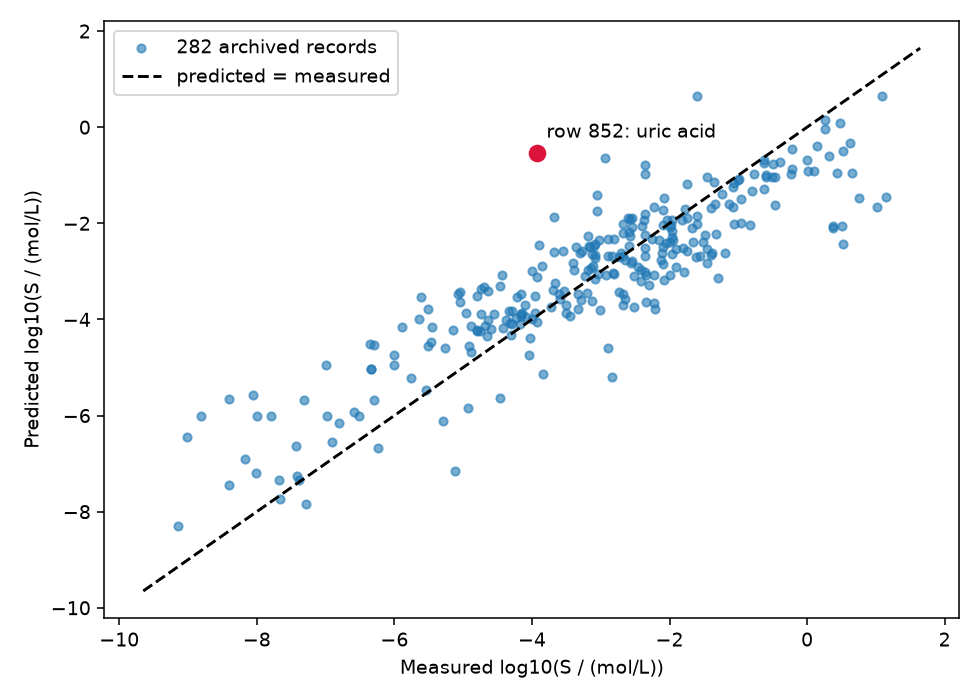

In [6]:
worst=max(guided,key=lambda r:abs(r['predicted']-r['measured']))
xs=[r['measured'] for r in guided];ys=[r['predicted'] for r in guided]
lo=min(xs+ys)-.5;hi=max(xs+ys)+.5
fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(xs,ys,s=18,alpha=.6,label='282 archived records')
ax.plot([lo,hi],[lo,hi],'k--',label='predicted = measured')
ax.scatter([worst['measured']],[worst['predicted']],color='crimson',s=65)
ax.annotate(f"row {worst['row_id']}: {worst['name']}",(worst['measured'],worst['predicted']),xytext=(5,8),textcoords='offset points')
ax.set(xlabel='Measured log10(S / (mol/L))',ylabel='Predicted log10(S / (mol/L))')
ax.legend();fig.tight_layout();fig.savefig(OUT/'parity.png',dpi=140)
display(Image(filename=str(OUT/'parity.png')));plt.close(fig)


### Из средней ошибки к необычной записи

Для row 852 (uric acid / мочевая кислота) наблюдаемый разрыв в этом snapshot велик. Вычислим его без округления исходных чисел. Кратность расхождения концентраций равна 10^|ε|. Не путайте её с 10^MAE: последнее характеризует геометрическое усреднение кратностей, а не верхнюю границу и не среднюю абсолютную ошибку концентрации.


{'row_id': 852,
 'name': 'uric acid',
 'smiles': 'O=c2[nH]c(=O)c1[nH]c(=O)[nH]c1[nH]2 ',
 'measured': -3.93,
 'predicted': -0.541,
 'residual_logS': 3.3890000000000002,
 'concentration_discrepancy_factor': 2449.0632418447467}

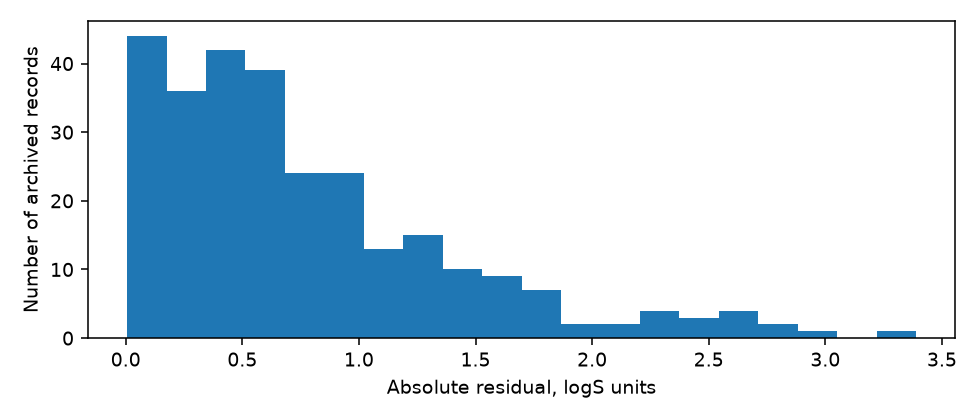

In [7]:
worst_error=worst['predicted']-worst['measured']
fold_gap=10**abs(worst_error)
display({**worst,'residual_logS':worst_error,'concentration_discrepancy_factor':fold_gap})
assert worst['row_id']==852 and math.isclose(abs(worst_error),3.389,abs_tol=1e-10)
assert fold_gap>1000
fig,ax=plt.subplots(figsize=(7,3))
ax.hist([abs(e) for e in residuals],bins=20)
ax.set(xlabel='Absolute residual, logS units',ylabel='Number of archived records')
fig.tight_layout();fig.savefig(OUT/'absolute_errors.png',dpi=140)
display(Image(filename=str(OUT/'absolute_errors.png')));plt.close(fig)


## 6. Как исследователь проверяет неожиданность

Наш вывод пока таков: усреднённая метрика не описывает риск каждой записи. Но мы **не установили**, почему именно эта запись расходится с прогнозом. Проверяем последовательно:

1. Не перепутаны ли predicted/measured и основание логарифма? Названия и код сохранены выше.
2. Те же ли байты источника? SHA256 проверен до и после анализа.
3. Есть ли условия измерения и неопределённость? В CSV их нет; значит, значимость и причину расхождения по одному числу не установить.
4. Проверяли ли мы новую молекулу независимо? Нет: analysed archive и независимый prospective test — разные доказательства.

Возможны ограничения модели, особенности объекта или несопоставимые условия; здесь это альтернативные гипотезы, а не приписанный статье механизм ошибки. Удалять неудобную строку, чтобы улучшить MAE, нельзя. Новый алгоритм тоже не заменяет аудит наблюдений.


In [8]:
assert checksum(raw_path)==raw_sha
audit={'source_sha256':raw_sha,'unit':META['units'],'missing_conditions':META['missing_conditions'],
       'claim':'archive comparison, not independent model validation','raw_unchanged':True}
print(audit)


{'source_sha256': '8c06a76f0c6487d29ab0f903e6a7a7139f189ab3c1178f159c8be8964602f189', 'unit': 'log10(S / (mol L^-1))', 'missing_conditions': ['pH', 'temperature', 'solid form', 'individual measurement uncertainty'], 'claim': 'archive comparison, not independent model validation', 'raw_unchanged': True}


## 7. Решение и следующий эксперимент

Разобранное решение: использовать прогноз как ограниченную гипотезу для планирования, сохраняя крупные расхождения в журнале. Для спорного образца сначала уточнить химическую форму и условия; затем предложить измерение растворимости при записанных pH/температуре с калибровкой, контролем и независимыми повторами. В этом notebook такое измерение **не выполнено**.

Если цель линии A — оценка CNS/A2A, даже безошибочный logS не измеряет проникновение через ГЭБ или связывание с рецептором. Нужно разложить вопрос на отдельные endpoints и выбрать соответствующие источники/эксперименты. В самостоятельной работе вы примените этот способ рассуждения к B: аторвастатин/HMGCR/печёночная экспозиция.

Альтернатива — сравнить другую модель на заранее выделенных независимых наблюдениях; если условий недостаточно, сначала собрать их. Критерий выбора следующего действия — какая проверка устранит наиболее важную неопределённость, а не какая даст красивее график.


In [9]:
run={'source':META['source_id'],'source_sha256':raw_sha,'subset_rule':'row_id % 4 == 0',
     'rows':len(guided),'MAE_logS':mae,'RMSE_logS':rmse,'worst_row':worst,
     'worst_residual_logS':worst_error,'fold_gap':fold_gap,'audit':audit,
     'python':sys.version,'executable':sys.executable,'experiment_performed':False}
(OUT/'guided_result.json').write_text(json.dumps(run,ensure_ascii=False,indent=2),encoding='utf-8')
print(OUT/'guided_result.json')


C:\Users\Miakhlov\Documents\GitHub\Computational chemistry_course\tmp\issue4-research-m01-20261117\tmp\m01-local-evidence\windows-20261117-inline\learner_work\guided\guided_result.json


## 8. Научный итог и карта

Мы сравнили готовые прогнозы и архивные наблюдения, получили средние ошибки и крупное локальное отклонение. Проверили шкалу и неизменность snapshot. Мы не воспроизвели fitting ESOL, не установили механизм ошибки, не измерили новую растворимость и не оценили печёночную/CNS-экспозицию.

Пример объяснённого ребра карты: **«остаток logS» → «соответствует кратному различию S»**, потому что логарифм десятичный; оговорка — это не оценка клинического эффекта. В следующем notebook добавьте собственную связь об условиях измерения или о границах переноса endpoint, с источником, объяснением и следующей проверкой.

Теперь ответьте на первоначальный вопрос заново: какой вывод вы готовы подписать и что изменило ваше решение? Сохраните собственную формулировку рядом с артефактами. [Переход к лабораторной](02_independent_lab.ipynb).

**Источники:** [Delaney, DOI](https://doi.org/10.1021/ci034243x); [конкретный snapshot и права](RESEARCH_SOURCE.md); [контекст A/B и отдельные endpoints](data/evidence_cards.json). Реплики и действия автору статьи не приписываются.
